In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('whitegrid')

In [4]:
### 1. Читання файлу 2017_jun_final.csv за допомогою методу read_csv

In [5]:
df = pd.read_csv('2017_jun_final.csv')
print("Файл успішно прочитано!")

Файл успішно прочитано!


In [6]:
# 2. Перегляд таблиці методом 'head'

In [7]:
df.head()

,N,Посада,Мова програмування,Спеціалізація,Загальний досвід роботи,Досвід роботи на поточному місці,Зарплата на місяць,Зміна зарплати за 12 місяців,Місто,Розмір компанії,...,Ще студент,Рівень англійської,Предметна область,Дата заповнення,User.Agent,exp,current_job_exp,salary,Валюта,cls
0,1,Junior QA engineer,NaN,Manual QA,0.5,0.5,400,0,Харків,до 10 осіб,...,True,Pre-intermediate (нище середнього),"iOS,eCommerce",12/06/2017 12:38:08,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,0.5,0.5,400,NaN,QA
1,2,Junior QA engineer,NaN,Manual QA,менше 3 місяців,менше 3 місяців,430,130,Харків,більше 1000 осіб,...,True,Upper-Intermediate (вище середнього),Веб-розробка,12/06/2017 12:42:51,Mozilla/5.0 (iPad; CPU OS 10_2_1 like Mac OS X...,0.0,0.0,430,NaN,QA
2,3,Software Engineer,C#/.NET,NaN,4,1,2500,800,Київ,до 1000 осіб,...,False,Intermediate (середній),"Веб-розробка,Корпоративні системи",12/06/2017 13:02:47,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,4.0,1.0,2500,NaN,DEV
3,4,Software Engineer,JavaScript,NaN,5,4,2000,400,Одеса,до 200 осіб,...,False,Pre-intermediate (нище середнього),"Desktop Applications,Веб-розробка",12/06/2017 13:03:01,Mozilla/5.0 (Windows NT 6.1; Win64; x64) Apple...,5.0,4.0,2000,NaN,DEV
4,5,Senior Software Engineer,JavaScript,NaN,10 і більше років,0.5,4500,500,Інше,до 10 осіб,...,False,Intermediate (середній),"Desktop Applications,Веб-розробка",12/06/2017 13:03:47,Mozilla/5.0 (iPhone; CPU iPhone OS 10_3_2 like...,10.0,0.5,4500,NaN,DEV


In [7]:
# 3. Розмір таблиці 'shape'

In [8]:
print(f"Розмір таблиці: {df.shape}")
print(f"Рядків: {df.shape[0]}, Стовпців: {df.shape[1]}")

Розмір таблиці: (8704, 25)
Рядків: 8704, Стовпців: 25


In [9]:
# 4. Типи стовпців 'dtypes'

In [10]:
print("Типи стовпців:")
print(df.dtypes)

Типи стовпців:
N                                     int64
Посада                               object
Мова програмування                   object
Спеціалізація                        object
Загальний досвід роботи              object
Досвід роботи на поточному місці     object
Зарплата на місяць                    int64
Зміна зарплати за 12 місяців          int64
Місто                                object
Розмір компанії                      object
Тип компанії                         object
Стать                                object
Вік                                   int64
Освіта                               object
Університет                          object
Ще студент                             bool
Рівень англійської                   object
Предметна область                    object
Дата заповнення                      object
User.Agent                           object
exp                                 float64
current_job_exp                     float64
salary           

In [11]:
# 5. Частка пропусків у кожній колонці

In [12]:
missing = df.isnull().sum() / len(df) * 100
print("Частка пропусків (%):")
print(missing.round(2))

Частка пропусків (%):
N                                    0.00
Посада                               0.00
Мова програмування                  44.23
Спеціалізація                       82.94
Загальний досвід роботи              0.00
Досвід роботи на поточному місці     0.00
Зарплата на місяць                   0.00
Зміна зарплати за 12 місяців         0.00
Місто                                0.00
Розмір компанії                      0.00
Тип компанії                         0.00
Стать                                0.00
Вік                                  0.00
Освіта                               0.00
Університет                          4.11
Ще студент                           0.00
Рівень англійської                   0.00
Предметна область                    2.56
Дата заповнення                      0.00
User.Agent                           0.00
exp                                  0.00
current_job_exp                      0.00
salary                               0.00
Валюта      

In [13]:
# 6. Видалення стовпців з пропусками, крім 'Мова.програмування'

In [8]:
lang = 'Мова програмування'
cols_to_drop = [c for c in df.columns if df[c].isnull().any() and c != lang]
print(cols_to_drop)
df = df.drop(columns=cols_to_drop)

['Спеціалізація', 'Університет', 'Предметна область', 'Валюта', 'cls']


In [15]:
# 7. Повторна перевірка пропусків

In [10]:
m = df.isnull().sum() / len(df)
print(m[m > 0])
assert list(m[m > 0].index) == [lang]

Мова програмування    0.442325
dtype: float64


In [17]:
# 8. Видалення рядків з пропусками 'dropna'

In [18]:
df = df.dropna()
print(f"Розмір після dropna: {df.shape}")

Розмір після dropna: (8704, 19)


In [19]:
# 9. Новий розмір таблиці

In [20]:
print(f"Новий розмір таблиці: {df.shape}")
print(f"Рядків: {df.shape[0]}, Стовпців: {df.shape[1]}")

Новий розмір таблиці: (8704, 19)
Рядків: 8704, Стовпців: 19


In [11]:
# 10. Нова таблиця 'python_data' — тільки Python-спеціалісти

In [13]:
python_data = df[df[lang] == 'Python']

In [39]:
# 11. Розмір 'python_data'

In [14]:
print(f"Розмір python_data: {python_data.shape}")

Розмір python_data: (207, 20)


In [15]:
# 12. Групування за стовпцем 'Посада'

In [16]:
grouped = python_data.groupby('Посада')
print("Групи за посадами:")
print(grouped.size())

Групи за посадами:
Посада
Junior Software Engineer     63
Senior Software Engineer     31
Software Engineer           100
System Architect              2
Technical Lead               11
dtype: int64


In [21]:
# 13. Агрегація: мін та макс зарплати за посадою

In [22]:
sal = 'Зарплата на місяць'
salary_stats = grouped.agg(min_salary=(sal, 'min'), max_salary=(sal, 'max'))
salary_stats

,min_salary,max_salary
Посада,,
Junior Software Engineer,100,1250
Senior Software Engineer,1300,9200
Software Engineer,500,5400
System Architect,3000,5000
Technical Lead,1425,6200


In [20]:
# 14. Функція 'fill_avg_salary' та новий стовпець 'avg'

In [24]:
def fill_avg_salary(row):
    return (row['min_salary'] + row['max_salary']) / 2

salary_stats['avg'] = salary_stats.apply(fill_avg_salary, axis=1)
salary_stats

,min_salary,max_salary,avg
Посада,,,
Junior Software Engineer,100,1250,675.0
Senior Software Engineer,1300,9200,5250.0
Software Engineer,500,5400,2950.0
System Architect,3000,5000,4000.0
Technical Lead,1425,6200,3812.5


In [25]:
# 15. Описова статистика для стовпця 'avg'

In [27]:
print("Описова статистика для стовпця 'avg':")
print(salary_stats['avg'].describe())

Описова статистика для стовпця 'avg':
count       5.000000
mean     3337.500000
std      1700.091909
min       675.000000
25%      2950.000000
50%      3812.500000
75%      4000.000000
max      5250.000000
Name: avg, dtype: float64


In [28]:
# 16. Збереження таблиці у CSV

In [29]:
output_file = 'python_data_result.csv'
python_data.to_csv(output_file, index=False)
print(f"Таблицю збережено у файл: {output_file}")
print(f"Рядків збережено: {len(python_data)}")

Таблицю збережено у файл: python_data_result.csv
Рядків збережено: 207


In [30]:
## Додаткова візуалізація (4 графіки різного типу)

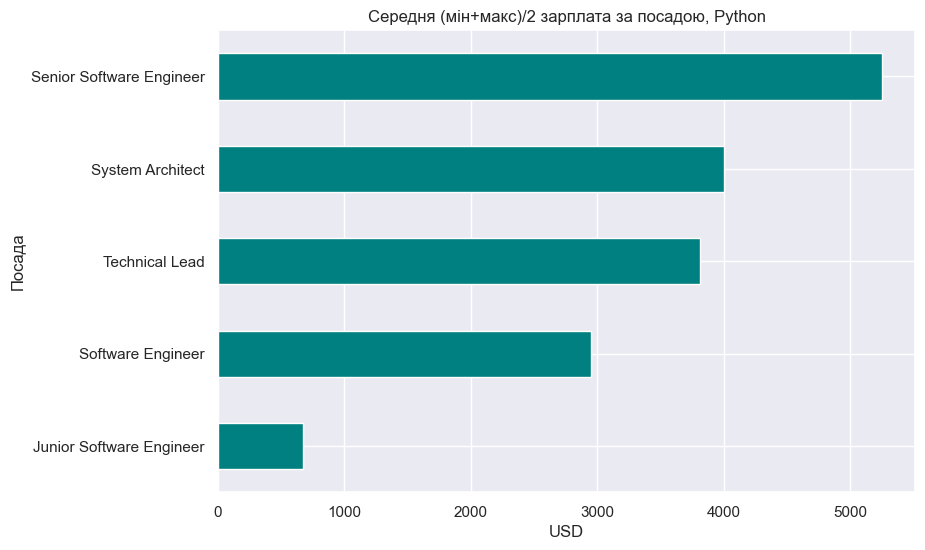

In [31]:
# 1) Горизонтальні стовпці: avg за посадою
sns.set_theme(style='darkgrid')
salary_stats['avg'].sort_values().plot.barh(figsize=(9,6), color='teal')
plt.title('Середня (мін+макс)/2 зарплата за посадою, Python')
plt.xlabel('USD')
plt.show()
sns.reset_orig()

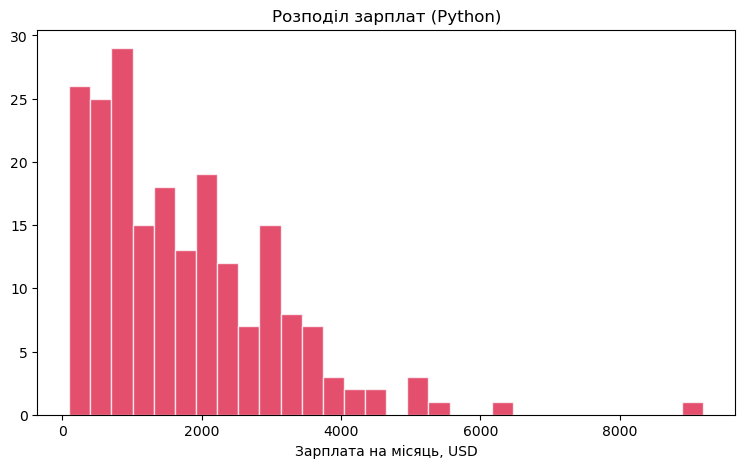

In [35]:
# 2) Гістограма зарплат Python-розробників
plt.figure(figsize=(9,5))
plt.hist(python_data[sal], bins=30, color='crimson', alpha=.75, edgecolor='white')
plt.title('Розподіл зарплат (Python)')
plt.xlabel('Зарплата на місяць, USD')
plt.show()

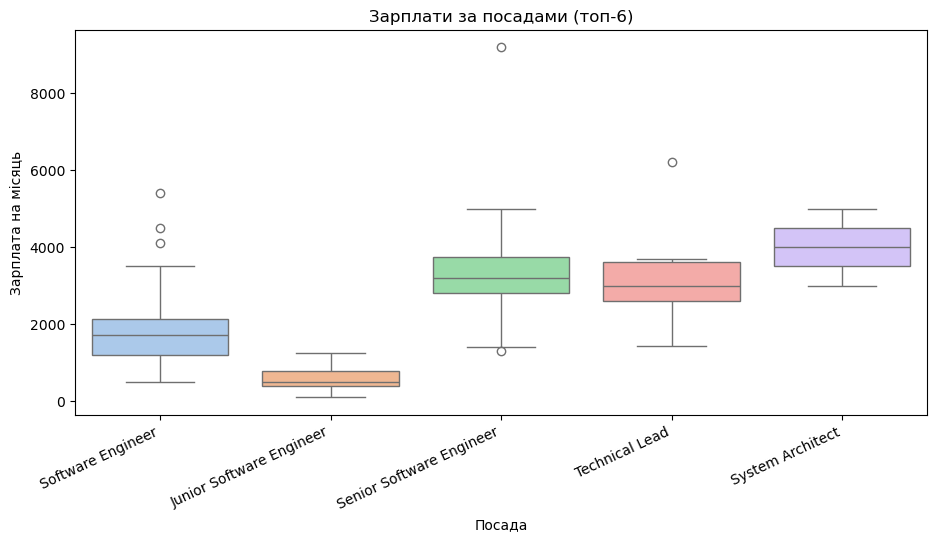

In [37]:
# 3) Boxplot зарплат за посадами (топ-6 за кількістю)
top = python_data['Посада'].value_counts().head(6).index
plt.figure(figsize=(11, 5))
sns.boxplot(
    data=python_data[python_data['Посада'].isin(top)],
    x='Посада', y=sal,
    hue='Посада', palette='pastel', legend=False
)
plt.xticks(rotation=25, ha='right')
plt.title('Зарплати за посадами (топ-6)')
plt.show()

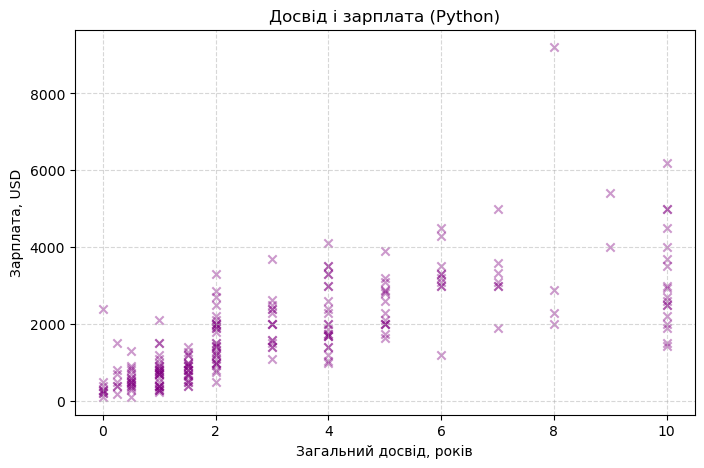

In [34]:
# 4) Scatter: досвід vs зарплата
plt.figure(figsize=(8,5))
plt.scatter(python_data['exp'], python_data[sal], alpha=.4, c='purple', marker='x')
plt.xlabel('Загальний досвід, років'); plt.ylabel('Зарплата, USD')
plt.title('Досвід і зарплата (Python)')
plt.grid(ls='--', alpha=.5)
plt.show()